# Analisis Riwayat Wish Genshin Impact (2021–2026)
**Proyek portofolio Data Analyst**

**Pertanyaan yang dijawab:**
1. Berapa rata-rata pull yang dibutuhkan untuk mendapat bintang 5?
2. Apakah *soft pity* (peluang naik drastis sekitar pull ke-74) terlihat di data nyata?
3. Seberapa sering menang / kalah 50/50?
4. Bagaimana pola pengeluaran pull dari waktu ke waktu?
5. Berapa "nilai setara rupiah" untuk satu bintang 5?

**Sumber data:** riwayat wish pribadi, diekspor dari paimon.moe (data sekunder, tanpa responden).

**Konteks untuk pembaca non-pemain:** Genshin Impact memakai sistem *gacha*. Satu "pull" = satu kali undian (160 Primogem).
Peluang dasar bintang 5 di banner karakter 0,6%, tapi dijamin keluar paling lambat di pull ke-90 (*hard pity*).
Saat bintang 5 keluar di banner karakter, ada peluang ~50% mendapat karakter yang sedang dipromosikan; kalau "kalah 50/50",
bintang 5 berikutnya dijamin karakter promosi.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Gaya grafik: garis tipis, grid samar
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8c8b85", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
BIRU, ORANYE, HIJAU_TOSKA = "#2a78d6", "#eb6834", "#1baf7a"

## 2. Upload file
Jalankan cell di bawah, lalu pilih file `paimonmoe_wish_history.xlsx` dari komputermu.
(Kalau tidak memakai Colab, cukup ubah variabel `FILE` ke lokasi file.)

In [2]:
FILE = "paimonmoe_wish_history.xlsx"
try:
    from google.colab import files
    uploaded = files.upload()
    FILE = list(uploaded.keys())[0]
except ImportError:
    pass  # bukan di Colab: pakai path FILE di atas
print("Memakai file:", FILE)

Saving paimonmoe_wish_history.xlsx to paimonmoe_wish_history.xlsx
Memakai file: paimonmoe_wish_history.xlsx


## 3. Load & cleaning data

In [3]:
SHEETS = {"Character Event": "Karakter", "Weapon Event": "Senjata", "Standard": "Standard"}

frames = []
for sheet, label in SHEETS.items():
    d = pd.read_excel(FILE, sheet_name=sheet)
    d["Jenis Banner"] = label
    d["Urutan"] = range(1, len(d) + 1)   # urutan asli pull di sheet (sudah kronologis)
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df = df.rename(columns={"⭐": "Rarity", "Type": "Tipe", "Name": "Nama", "Time": "Waktu"})
df["Waktu"] = pd.to_datetime(df["Waktu"])
df = df.sort_values(["Jenis Banner", "Urutan"]).reset_index(drop=True)

# Cek kualitas data
print("Total pull:", len(df))
print("Data kosong per kolom:")
print(df[["Tipe", "Nama", "Waktu", "Rarity", "Pity"]].isna().sum())
df.head()

Total pull: 7115
Data kosong per kolom:
Tipe      0
Nama      0
Waktu     0
Rarity    0
Pity      0
dtype: int64


,Tipe,Nama,Waktu,Rarity,Pity,#Roll,Group,Banner,Part,Jenis Banner,Urutan
0,Weapon,Slingshot,2021-11-02 18:22:06,3,1,1,1,Moment of Bloom,NaN,Karakter,1
1,Weapon,Sharpshooter's Oath,2021-11-02 18:22:14,3,1,2,2,Moment of Bloom,NaN,Karakter,2
2,Weapon,Ferrous Shadow,2021-11-02 18:22:21,3,1,3,3,Moment of Bloom,NaN,Karakter,3
3,Weapon,Bloodtainted Greatsword,2021-11-02 18:22:27,3,1,4,4,Moment of Bloom,NaN,Karakter,4
4,Weapon,Favonius Codex,2021-11-02 18:22:33,4,5,5,5,Moment of Bloom,NaN,Karakter,5


**Hitung ulang pity sendiri.** Kolom `Pity` bawaan paimon.moe dihitung per rarity, jadi untuk analisis peluang
kita butuh penghitung "pull ke berapa sejak bintang 5 terakhir" untuk *setiap* baris.

In [4]:
def hitung_pity5(g):
    pity, out = 0, []
    for r in g["Rarity"]:
        pity += 1
        out.append(pity)
        if r == 5:
            pity = 0
    return pd.Series(out, index=g.index)

df["Pity5"] = df.groupby("Jenis Banner", group_keys=False).apply(hitung_pity5)
bintang5 = df[df["Rarity"] == 5].copy()

# Validasi: pity hasil hitungan sendiri harus sama dengan kolom Pity bawaan untuk bintang 5
print("Pity cocok dengan paimon.moe:", (bintang5["Pity5"] == bintang5["Pity"]).all())
bintang5[["Jenis Banner", "Nama", "Waktu", "Pity5"]].tail(10)

Pity cocok dengan paimon.moe: True


/tmp/ipykernel_1890/1668387587.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df["Pity5"] = df.groupby("Jenis Banner", group_keys=False).apply(hitung_pity5)


,Jenis Banner,Nama,Waktu,Pity5
6482,Standard,Skyward Spine,2023-01-01 12:21:23,9
6557,Standard,Keqing,2023-06-07 10:17:48,75
6635,Standard,Skyward Blade,2023-11-16 14:03:38,78
6708,Standard,Tighnari,2024-04-29 10:59:56,73
6786,Standard,Skyward Pride,2024-11-03 22:55:41,78
6816,Standard,Skyward Harp,2025-05-07 11:26:16,30
6876,Standard,Mona,2025-07-07 16:25:57,60
6954,Standard,Tighnari,2025-10-13 19:57:20,78
7034,Standard,Skyward Pride,2026-03-01 06:40:03,80
7109,Standard,Tighnari,2026-09-23 20:11:14,75


## 4. Gambaran umum

In [5]:
ringkas = df.groupby("Jenis Banner").agg(
    Total_Pull=("Nama", "size"),
    Mulai=("Waktu", "min"),
    Terakhir=("Waktu", "max"),
    Bintang_5=("Rarity", lambda r: (r == 5).sum()),
    Bintang_4=("Rarity", lambda r: (r == 4).sum()),
)
ringkas["Rata2_Pull_per_B5"] = (ringkas["Total_Pull"] / ringkas["Bintang_5"]).round(1)
ringkas["Mulai"] = ringkas["Mulai"].dt.date
ringkas["Terakhir"] = ringkas["Terakhir"].dt.date
ringkas

,Total_Pull,Mulai,Terakhir,Bintang_5,Bintang_4,Rata2_Pull_per_B5
Jenis Banner,,,,,,
Karakter,4593,2021-11-02,2026-11-04,76,600,60.4
Senjata,1660,2021-11-07,2026-10-07,30,250,55.3
Standard,862,2021-10-13,2026-09-23,15,112,57.5


## 5. Distribusi pity bintang 5 — apakah *soft pity* terlihat?

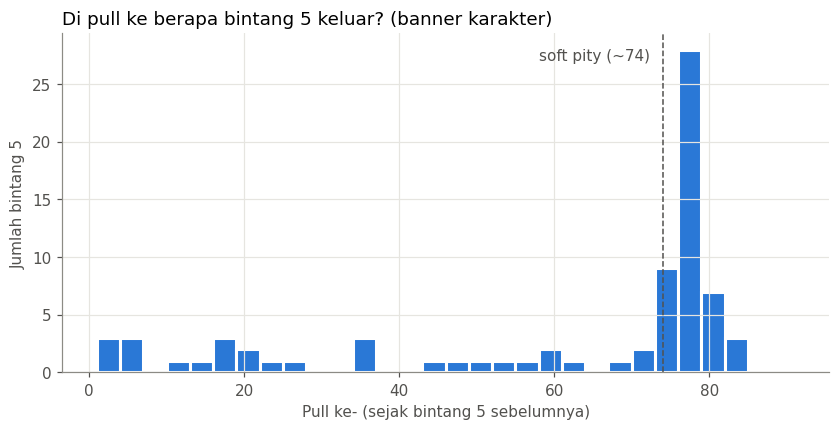

Rata-rata pity  : 60.0
Median pity     : 76
Keluar di pull 74–90: 62% dari semua bintang 5


In [6]:
karakter5 = bintang5[bintang5["Jenis Banner"] == "Karakter"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(karakter5["Pity5"], bins=range(1, 92, 3), color=BIRU, edgecolor="white", linewidth=2)
ax.axvline(74, color="#52514e", linestyle="--", linewidth=1)
ax.text(73, ax.get_ylim()[1] * 0.92, "soft pity (~74) ", color="#52514e", ha="right")
ax.set_title("Di pull ke berapa bintang 5 keluar? (banner karakter)", loc="left", fontsize=12)
ax.set_xlabel("Pull ke- (sejak bintang 5 sebelumnya)")
ax.set_ylabel("Jumlah bintang 5")
plt.show()

print(f"Rata-rata pity  : {karakter5['Pity5'].mean():.1f}")
print(f"Median pity     : {karakter5['Pity5'].median():.0f}")
print(f"Keluar di pull 74–90: {(karakter5['Pity5'] >= 74).mean():.0%} dari semua bintang 5")

### Peluang bintang 5 di tiap pull (*hazard rate*)
Pertanyaannya: *kalau sudah sampai pull ke-n tanpa bintang 5, berapa peluang pull ke-n itu memberi bintang 5?*
Ini cara yang lebih tepat untuk melihat soft pity daripada histogram biasa.

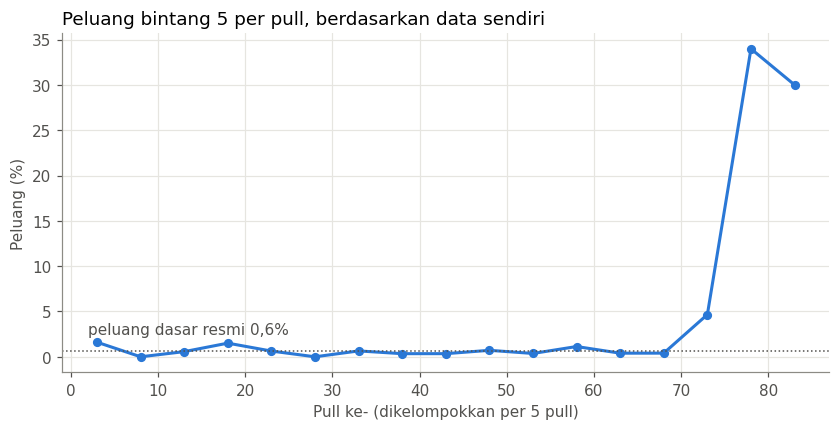

Peluang rata-rata pull 1–73 : 0.66%
Peluang rata-rata pull 74+  : 23.04%


In [7]:
kar = df[df["Jenis Banner"] == "Karakter"]
sampai = kar.groupby("Pity5").size()                       # berapa kali pull ke-n terjadi
dapat = kar[kar["Rarity"] == 5].groupby("Pity5").size()     # berapa kali pull ke-n = bintang 5
hazard = (dapat.reindex(sampai.index, fill_value=0) / sampai).rename("Peluang")

# gabungkan per 5 pull supaya tidak terlalu "berisik"
blok = (hazard.index - 1) // 5 * 5 + 1
hz = pd.DataFrame({"sampai": sampai, "dapat": dapat.reindex(sampai.index, fill_value=0)})
hz_blok = hz.groupby(blok).sum()
hz_blok["Peluang"] = hz_blok["dapat"] / hz_blok["sampai"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hz_blok.index + 2, hz_blok["Peluang"] * 100, color=BIRU, linewidth=2, marker="o", markersize=5)
ax.axhline(0.6, color="#52514e", linestyle=":", linewidth=1)
ax.text(2, 2.5, "peluang dasar resmi 0,6%", color="#52514e")
ax.set_title("Peluang bintang 5 per pull, berdasarkan data sendiri", loc="left", fontsize=12)
ax.set_xlabel("Pull ke- (dikelompokkan per 5 pull)")
ax.set_ylabel("Peluang (%)")
plt.show()

print(f"Peluang rata-rata pull 1–73 : {hz.loc[:73,'dapat'].sum()/hz.loc[:73,'sampai'].sum():.2%}")
print(f"Peluang rata-rata pull 74+  : {hz.loc[74:,'dapat'].sum()/hz.loc[74:,'sampai'].sum():.2%}")

## 6. Menang / kalah 50/50
Bintang 5 dianggap **kalah 50/50** jika yang keluar karakter *standard* (bukan karakter promosi).
Daftar karakter standard bertambah dari waktu ke waktu, jadi kita pakai **tanggal masuk** masing-masing:
- Tighnari masuk standard di versi 3.1 (28 Sep 2022)
- Dehya di versi 3.6 (12 Apr 2023)
- Yumemizuki Mizuki di versi 5.5 (26 Mar 2025)

Kalau ada karakter standard baru setelah ini, tambahkan ke dictionary di bawah.

Status tiap bintang 5:
- **Kalah** = dapat karakter standard
- **Dijamin** = bintang 5 sebelumnya kalah, jadi yang ini pasti karakter promosi (tidak dihitung sebagai 50/50)
- **Menang** = dapat karakter promosi tanpa jaminan

In [8]:
STANDARD = {
    "Diluc": "2020-01-01", "Jean": "2020-01-01", "Qiqi": "2020-01-01",
    "Mona": "2020-01-01", "Keqing": "2020-01-01",
    "Tighnari": "2022-09-28", "Dehya": "2023-04-12", "Yumemizuki Mizuki": "2025-03-26",
}
STANDARD = {k: pd.Timestamp(v) for k, v in STANDARD.items()}

def is_standard(row):
    return row["Nama"] in STANDARD and row["Waktu"] >= STANDARD[row["Nama"]]

k5 = karakter5.sort_values("Urutan").copy()
status, kalah_sebelumnya = [], False
for _, row in k5.iterrows():
    if kalah_sebelumnya:
        status.append("Dijamin"); kalah_sebelumnya = False
    elif is_standard(row):
        status.append("Kalah"); kalah_sebelumnya = True
    else:
        status.append("Menang")
k5["Status"] = status

hasil = k5["Status"].value_counts()
menang, kalah = hasil.get("Menang", 0), hasil.get("Kalah", 0)
print(hasil.to_string())
print(f"\nWin rate 50/50: {menang}/{menang+kalah} = {menang/(menang+kalah):.0%}")

Status
Menang     28
Kalah      24
Dijamin    24

Win rate 50/50: 28/52 = 54%


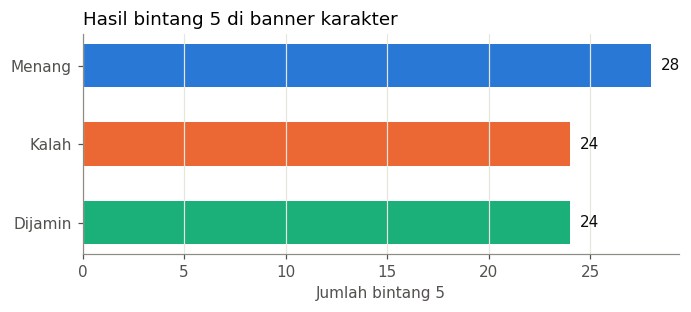

,count
Nama,
Mona,5
Keqing,5
Tighnari,3
Diluc,3
Jean,3
Dehya,2
Qiqi,2
Yumemizuki Mizuki,1


In [9]:
fig, ax = plt.subplots(figsize=(7, 2.6))
urutan = ["Menang", "Kalah", "Dijamin"]
nilai = [hasil.get(s, 0) for s in urutan]
ax.barh(urutan, nilai, color=[BIRU, ORANYE, HIJAU_TOSKA], height=0.55)
for y, v in enumerate(nilai):
    ax.text(v + 0.5, y, str(v), va="center", color="#0b0b0b")
ax.invert_yaxis()
ax.set_title("Hasil bintang 5 di banner karakter", loc="left", fontsize=12)
ax.set_xlabel("Jumlah bintang 5")
ax.grid(axis="y", visible=False)
plt.show()

# Daftar karakter yang membuat kalah 50/50
k5[k5["Status"] == "Kalah"]["Nama"].value_counts()

## 7. Pola pull dari waktu ke waktu

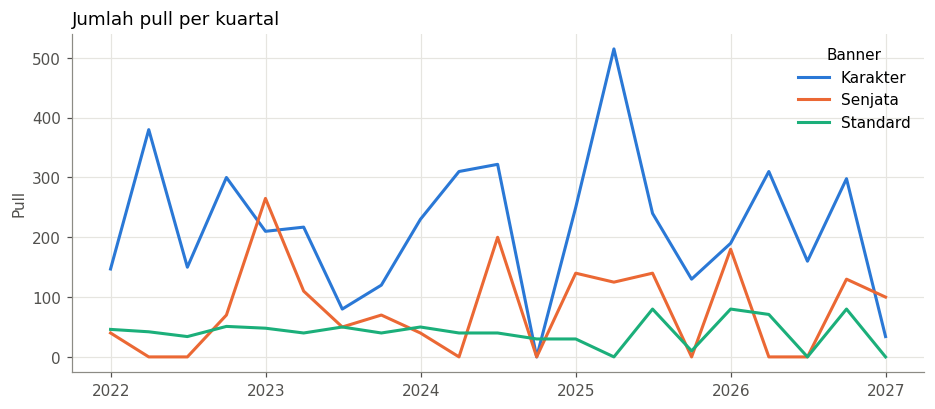

Jenis Banner,Karakter,Senjata,Standard,Total
Tahun,,,,
2021,147,40,46,233
2022,1040,335,175,1550
2023,647,270,180,1097
2024,882,340,140,1362
2025,1075,445,170,1690
2026,802,230,151,1183


In [10]:
per_bulan = (df.set_index("Waktu").groupby("Jenis Banner").resample("QE").size()
               .unstack(0).fillna(0))

fig, ax = plt.subplots(figsize=(10, 4))
warna = {"Karakter": BIRU, "Senjata": ORANYE, "Standard": HIJAU_TOSKA}
for kol in ["Karakter", "Senjata", "Standard"]:
    if kol in per_bulan:
        ax.plot(per_bulan.index, per_bulan[kol], label=kol, color=warna[kol], linewidth=2)
ax.set_title("Jumlah pull per kuartal", loc="left", fontsize=12)
ax.set_ylabel("Pull")
ax.legend(frameon=False, title="Banner")
plt.show()

per_tahun = df.groupby([df["Waktu"].dt.year.rename("Tahun"), "Jenis Banner"]).size().unstack(fill_value=0)
per_tahun["Total"] = per_tahun.sum(axis=1)
per_tahun

## 8. Nilai setara rupiah
1 pull = 160 Primogem = 160 Genesis Crystal. Harga paket diambil dari harga top-up reseller Indonesia
(paket 6480+1600 Crystal ≈ Rp1.629.000, Agustus 2026). **Ubah angka ini kalau harga berubah.**

Catatan penting: sebagian besar pull biasanya berasal dari Primogem gratis, jadi angka ini adalah
**nilai setara**, bukan uang yang benar-benar dikeluarkan.

In [11]:
HARGA_PAKET = 1_629_000     # Rupiah
CRYSTAL_PER_PAKET = 6480 + 1600
RP_PER_PULL = HARGA_PAKET / CRYSTAL_PER_PAKET * 160

biaya = ringkas[["Total_Pull", "Bintang_5"]].copy()
biaya["Nilai_Total_Rp"] = biaya["Total_Pull"] * RP_PER_PULL
biaya["Rp_per_Bintang5"] = biaya["Nilai_Total_Rp"] / biaya["Bintang_5"]
print(f"Nilai setara 1 pull: Rp{RP_PER_PULL:,.0f}".replace(",", "."))
biaya.style.format({"Nilai_Total_Rp": "Rp{:,.0f}", "Rp_per_Bintang5": "Rp{:,.0f}"})

Nilai setara 1 pull: Rp32.257


,Total_Pull,Bintang_5,Nilai_Total_Rp,Rp_per_Bintang5
Jenis Banner,,,,
Karakter,4593,76,"Rp148,158,356","Rp1,949,452"
Senjata,1660,30,"Rp53,547,327","Rp1,784,911"
Standard,862,15,"Rp27,805,901","Rp1,853,727"


## 9. Ringkasan insight

In [12]:
total = len(df)
print(f"• Total {total:,} pull dari {df['Waktu'].min():%b %Y} sampai {df['Waktu'].max():%b %Y}.".replace(",", "."))
print(f"• Banner karakter: rata-rata {karakter5['Pity5'].mean():.1f} pull per bintang 5; "
      f"{(karakter5['Pity5'] >= 74).mean():.0%} bintang 5 keluar di pull 74 ke atas → soft pity terkonfirmasi.")
print(f"• Peluang bintang 5 naik dari {hz.loc[:73,'dapat'].sum()/hz.loc[:73,'sampai'].sum():.1%} (pull 1–73) "
      f"menjadi {hz.loc[74:,'dapat'].sum()/hz.loc[74:,'sampai'].sum():.1%} (pull 74+).")
print(f"• Win rate 50/50: {menang/(menang+kalah):.0%} ({menang} menang, {kalah} kalah).")
print(f"• Nilai setara satu bintang 5 di banner karakter ≈ "
      f"Rp{biaya.loc['Karakter','Rp_per_Bintang5']:,.0f}.".replace(",", "."))

• Total 7.115 pull dari Oct 2021 sampai Nov 2026.
• Banner karakter: rata-rata 60.0 pull per bintang 5; 62% bintang 5 keluar di pull 74 ke atas → soft pity terkonfirmasi.
• Peluang bintang 5 naik dari 0.7% (pull 1–73) menjadi 23.0% (pull 74+).
• Win rate 50/50: 54% (28 menang, 24 kalah).
• Nilai setara satu bintang 5 di banner karakter ≈ Rp1.949.452.


**Keterbatasan:**
- Ini data satu akun, jadi hasilnya bisa berbeda dari rata-rata semua pemain.
- Status 50/50 disimpulkan dari daftar karakter standard. Mekanisme *Capturing Radiance* (sejak versi 5.0) bisa
  memengaruhi peluang menang dan tidak terlihat langsung di data.
- Nilai rupiah adalah estimasi berbasis harga top-up, bukan pengeluaran sebenarnya.

**Ide lanjutan:** bandingkan dengan dataset komunitas, analisis banner senjata (Epitomized Path), atau uji statistik
apakah win rate 50/50 berbeda signifikan dari 50% (*binomial test*).